# Оптимизация гиперпараметров
Датасет **Titanic-Dataset**: 
- целевая переменная - **Survived** 


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import kagglehub
from kagglehub import KaggleDatasetAdapter

%matplotlib inline
sns.set_theme(style="darkgrid")

file_path = "Titanic-Dataset.csv"

df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "yasserh/titanic-dataset",
  file_path,
)


pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

print(df.shape)
print(df.head())
print(df["Survived"].describe())

print("Количество пропусков в каждом столбце:")
display(df.isna().sum().to_frame(name="missing_values").T)
print(f"Количество полных дубликатов строк: {df.duplicated().sum()}")

(891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN    

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
missing_values,0,0,0,0,0,177,0,0,0,0,687,2


Количество полных дубликатов строк: 0


**Объем и целостность данных:** Датасет содержит 891 объект и 12 столбцов (числовые: `Age`, `Fare`, `SibSp`, `Parch`; порядковые/бинарные: `Survived`, `Pclass`; строковые/категориальные: `Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`). Полных дубликатов строк нет. Много пропусков номера кабины, меньше - возраст и порт посадки

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


RANDOM_STATE = 42

def extract_deterministic_features(df_in):
    d = df_in.copy()
    
    d['Age_is_missing'] = d['Age'].isna().astype(int)
    d['Has_Cabin'] = d['Cabin'].notna().astype(int)
    
    cabin_map = {'A': 8, 'B': 7, 'C': 6, 'D': 5, 'E': 4, 'F': 3, 'G': 2, 'T': 1}
    d['Cabin'] = d['Cabin'].str[0].map(cabin_map).fillna(0).astype(int)
    
    d['Sex'] = d['Sex'].map({'male': 1, 'female': 0})
    d['Pclass'] = d['Pclass'].map({1: 3, 2: 2, 3: 1})
    return d

class GroupMedianAgeImputer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.group_medians_ = X.groupby(['Pclass', 'Sex'])['Age'].median()
        self.global_median_ = X['Age'].median()
        return self

    def transform(self, X):
        X_out = X.copy()
        mapped_age = (
            X_out.set_index(['Pclass', 'Sex'])
            .index.map(self.group_medians_)
            .to_series(index=X_out.index)
        )
        X_out['Age'] = X_out['Age'].fillna(mapped_age).fillna(self.global_median_)
        return X_out

numeric_features = ['Age', 'Fare', 'SibSp', 'Parch', 'Pclass', 'Cabin', 'Sex', 'Age_is_missing']
categorical_features = ['Embarked']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

column_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

preprocessor = Pipeline(steps=[
    ('feature_extraction', FunctionTransformer(extract_deterministic_features)),
    ('age_group_imputer', GroupMedianAgeImputer()),
    ('column_processing', column_preprocessor)
])

### Предобработка данных:
Первичный анализ данных пропущен, т.к. был произведён в прошлой ЛР. Полученные с прошлой ЛР данные будут переиспользованы для заполнения пропусков. Ключевые моменты:

- **Обработка пропусков и категорий:**
   * `Embarked` (2 пропуска): заполняется модой (`most_frequent`) и кодируется через `OneHotEncoder` в 3 бинарных признака, так как между портами посадки нельзя определить, какой больше влияет на выживаемость.
   * `Cabin` (687 пропусков): извлекается первая буква палубы и переводится в порядковую шкалу от `1` (нижняя палуба `T`) до `8` (верхняя палуба `A`), а пропуски кодируются как `0`.
   * `Age` (177 пропусков): заполняется медианным возрастом внутри групп `['Pclass', 'Sex']` (с помощью кастомного трансформера `GroupMedianAgeImputer`), так как возраст заметно коррелирует с классом билета (0.41). Дополнительно сохраняется бинарный индикатор пропуска `Age_is_missing`.


In [21]:
from sklearn.model_selection import GridSearchCV, cross_val_predict
import time


X = df.drop(columns=["Survived"])
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

pipe = Pipeline([ 
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=RANDOM_STATE))
])

param_grid = { 
    'classifier__n_estimators': [100, 150, 250],
    'classifier__learning_rate': [0.05, 0.075, 0.1, 0.15],
    'classifier__max_depth': [2, 3, 5],
    'classifier__subsample': [0.6, 1.0]
} # всего 72 комбинации


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(
    pipe,               
    param_grid=param_grid,
    cv=skf,
    scoring='f1',
    n_jobs=-1
)

t0 = time.perf_counter()
grid_search.fit(X_train, y_train)
grid_time = time.perf_counter() - t0

best_comp_pipe_grd = grid_search.best_estimator_
print("GridSearch")
print(f"Время подбора параметров: {grid_time}")
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"F1 на 5-fold CV (при стандартном пороге 0.50): {grid_search.best_score_:.4f}")

best_idx = grid_search.best_index_
cv_results = grid_search.cv_results_

fold_f1_scores = [
    cv_results[f'split{i}_test_score'][best_idx]
    for i in range(grid_search.n_splits_)
]

print("F1 по фолдам:")
for i, score in enumerate(fold_f1_scores, start=1):
    print(f"\tFold {i}: {score:.4f}")

GridSearch
Время подбора параметров: 15.572185299941339
Лучшие параметры: {'classifier__learning_rate': 0.075, 'classifier__max_depth': 3, 'classifier__n_estimators': 150, 'classifier__subsample': 0.6}
F1 на 5-fold CV (при стандартном пороге 0.50): 0.7760
F1 по фолдам:
	Fold 1: 0.8037
	Fold 2: 0.7339
	Fold 3: 0.8000
	Fold 4: 0.7500
	Fold 5: 0.7921


Получили лучшие значения Grid Search

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

param_dist = {
    'classifier__n_estimators': randint(100, 251),
    'classifier__learning_rate': loguniform(0.05, 0.15),
    'classifier__max_depth': randint(2, 6),
    'classifier__subsample': uniform(0.6, 0.4)
}

random_search = RandomizedSearchCV(
    estimator=pipe,
    param_distributions=param_dist,
    n_iter=70,
    scoring="f1",
    cv=skf,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

t0 = time.perf_counter()
random_search.fit(X_train, y_train)
rand_time = time.perf_counter() - t0

best_comp_pipe_rnd = random_search.best_estimator_
print("RandomSearch")
print(f"Время подбора параметров: {rand_time}")
print(f"Лучшие параметры: {random_search.best_params_}")
print(f"F1 на 5-fold CV (при стандартном пороге 0.50): {random_search.best_score_:.4f}")

best_idx = random_search.best_index_
cv_results = random_search.cv_results_

fold_f1_scores = [
    cv_results[f'split{i}_test_score'][best_idx]
    for i in range(random_search.n_splits_)
]

print("F1 по фолдам:")
for i, score in enumerate(fold_f1_scores, start=1):
    print(f"\tFold {i}: {score:.4f}")


RandomSearch
Время подбора параметров: 16.035725999972783
Лучшие параметры: {'classifier__learning_rate': np.float64(0.08959632138250487), 'classifier__max_depth': 3, 'classifier__n_estimators': 167, 'classifier__subsample': np.float64(0.632341330533086)}
F1 на 5-fold CV (при стандартном пороге 0.50): 0.7690
F1 по фолдам:
	Fold 1: 0.8190
	Fold 2: 0.7339
	Fold 3: 0.7961
	Fold 4: 0.7387
	Fold 5: 0.7573


Получили лучшие значения Random Search

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_validate
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, confusion_matrix


base_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=2,
        random_state=RANDOM_STATE
    ))
])

base_CV = cross_validate(
    base_pipe, 
    X_train, y_train,
    cv=skf, 
    scoring='f1',
    n_jobs=-1, 
    return_train_score=False
)
t0 = time.perf_counter()
base_pipe.fit(X_train, y_train)
base_time = time.perf_counter() - t0

base_fold_scores = base_CV['test_score']
base_CV_mean = base_fold_scores.mean()
base_CV_std = base_fold_scores.std()

print("Исходная модель")
print(f"F1 на 5-fold CV: {base_CV_mean:.4f} ± {base_CV_std:.4f}")
print("F1 по фолдам:")
for i, score in enumerate(base_fold_scores, start=1):
    print(f"\tFold {i}: {score:.4f}")


Исходная модель
F1 на 5-fold CV: 0.7586 ± 0.0356
F1 по фолдам:
	Fold 1: 0.8113
	Fold 2: 0.7156
	Fold 3: 0.7879
	Fold 4: 0.7455
	Fold 5: 0.7327


Восстановили данные исходной модели


Сводная таблица результатов:


,Модель,Комбинаций,"Время (сек, сумм. CPU)",CV F1 (Mean),Test F1
0,Исходная,1,0.18,0.7586,0.7132
1,Grid Search,72,178.19,0.7760,0.6929
2,Random Search,70,184.56,0.7690,0.7188


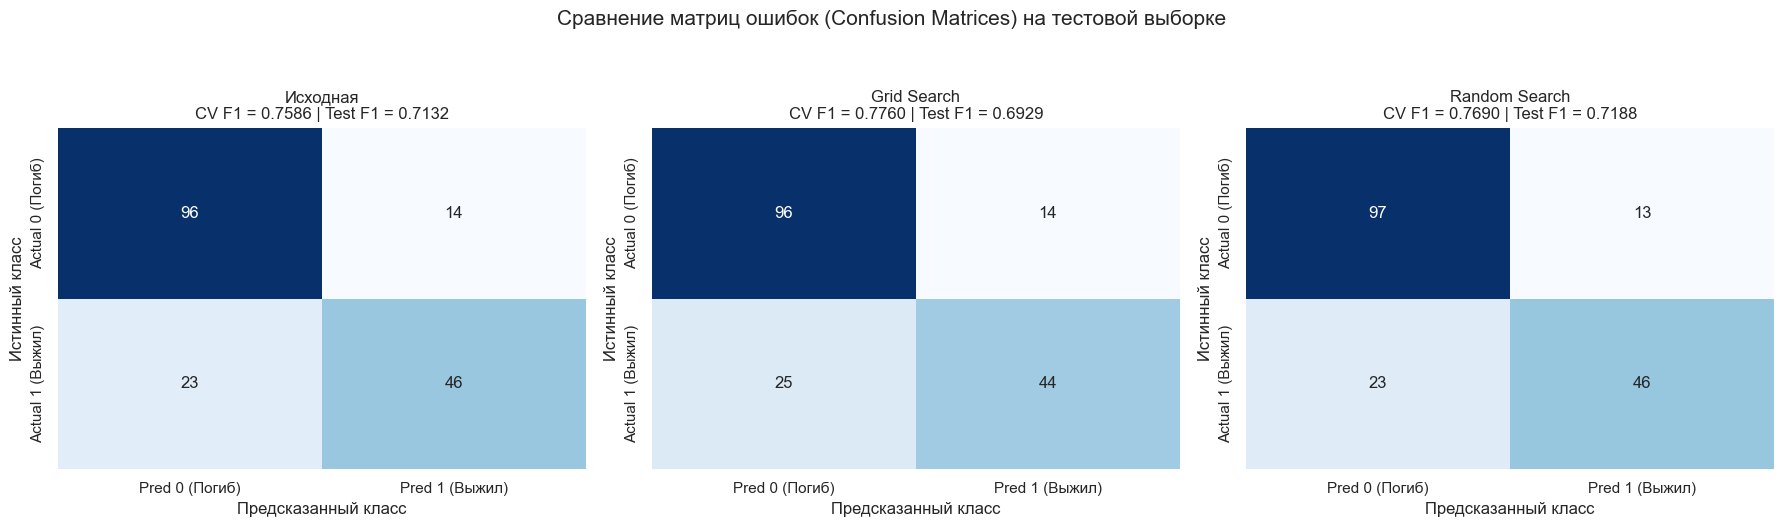

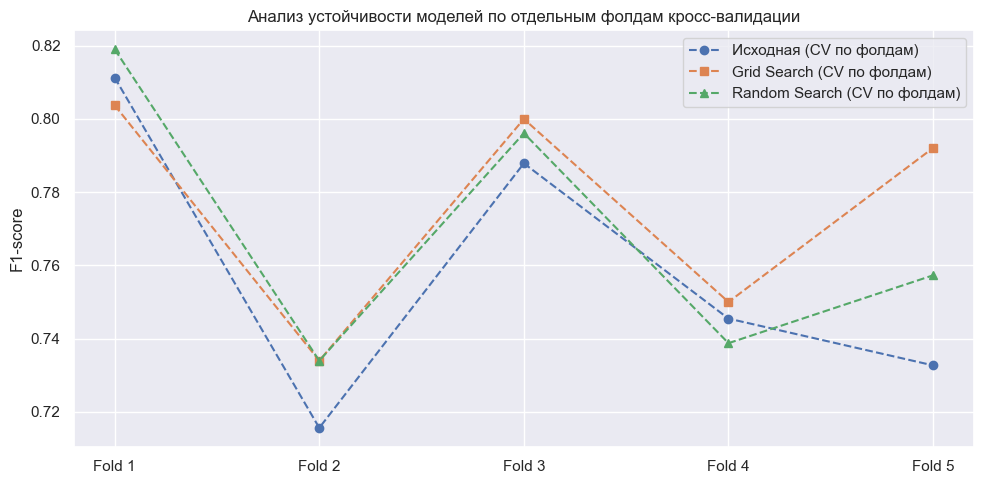

In [30]:
def extract_search_stats(search_obj, name, X_test, y_test):
    best_idx = search_obj.best_index_
    cv_res = search_obj.cv_results_
    n_splits = search_obj.n_splits_
    
    fold_scores = np.array([cv_res[f'split{i}_test_score'][best_idx] for i in range(n_splits)])
    n_combinations = len(cv_res['params'])
    
    # Оценка суммарного времени (обучение + скоринг всех комбинаций на всех фолдах + refit)
    total_cv_time = ((cv_res['mean_fit_time'].sum() + cv_res['mean_score_time'].sum()) * n_splits + getattr(search_obj, 'refit_time_', 0.0))
    
    best_model = search_obj.best_estimator_
    y_pred = best_model.predict(X_test)
    
    return {
        'Модель': name,
        'Комбинаций': n_combinations,
        'Время (сек, сумм. CPU)': round(total_cv_time, 2),
        'CV F1 (Mean)': fold_scores.mean(),
        'Test F1': f1_score(y_test, y_pred, zero_division=0),
        'y_pred': y_pred,
        'fold_scores': fold_scores
    }

y_pred_base = base_pipe.predict(X_test)
base_stats = {
    'Модель': 'Исходная',
    'Комбинаций': 1,
    'Время (сек, сумм. CPU)': round(base_time, 2),
    'CV F1 (Mean)': base_CV_mean,
    'Test F1': f1_score(y_test, y_pred_base, zero_division=0),
    'y_pred': y_pred_base,
    'fold_scores': base_fold_scores
}

grd_stats = extract_search_stats(grid_search, 'Grid Search', X_test, y_test)
rnd_stats = extract_search_stats(random_search, 'Random Search', X_test, y_test)

all_stats = [base_stats, grd_stats, rnd_stats]

summary_df = pd.DataFrame([
    {k: v for k, v in st.items() if k not in ('y_pred', 'fold_scores')}
    for st in all_stats
])

print("\nСводная таблица результатов:")
display(summary_df.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, st in zip(axes, all_stats):
    cm = confusion_matrix(y_test, st['y_pred'])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Pred 0 (Погиб)", "Pred 1 (Выжил)"],
        yticklabels=["Actual 0 (Погиб)", "Actual 1 (Выжил)"]
    )
    ax.set_title(
        f"{st['Модель']}\nCV F1 = {st['CV F1 (Mean)']:.4f} | Test F1 = {st['Test F1']:.4f}"
    )
    ax.set_ylabel("Истинный класс")
    ax.set_xlabel("Предсказанный класс")

plt.suptitle("Сравнение матриц ошибок (Confusion Matrices) на тестовой выборке", fontsize=15, y=1.05)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
x_pos = np.arange(1, skf.get_n_splits() + 1)

for st, marker in zip(all_stats, ['o', 's', '^']):
    ax.plot(x_pos, st['fold_scores'], marker=marker, linestyle='--', label=f"{st['Модель']} (CV по фолдам)")

ax.set_xticks(x_pos)
ax.set_xticklabels([f"Fold {i}" for i in x_pos])
ax.set_ylabel("F1-score")
ax.set_title("Анализ устойчивости моделей по отдельным фолдам кросс-валидации")
ax.legend()
plt.tight_layout()
plt.show()